# 2026 — mHC: Manifold-Constrained Hyper-Connections

**Papers:** Zhu et al., *"Hyper-Connections"* (ByteDance, 2024); DeepSeek-AI, *"mHC: Manifold-Constrained Hyper-Connections"* (arXiv 2512.24880, January 2026). In production: **DeepSeek-V4** (2026) uses mHC with $n=4$ streams in every layer.

Since ResNet (notebook 29), every deep network has had **one** residual stream: $x_{l+1} = x_l + F(x_l)$. **Hyper-Connections (HC)** widen it to $n$ parallel streams $X_l \in \mathbb R^{n\times C}$ and *learn* how layers read from, write to and mix them:

$$X_{l+1} = H^{res}_l X_l + {H^{post}_l}^{\!\top} F\big(H^{pre}_l X_l\big)$$

- $H^{pre} \in \mathbb R^{1\times n}$ chooses what the layer reads (a weighted sum of streams)
- $H^{post} \in \mathbb R^{1\times n}$ distributes the layer's output over the streams
- $H^{res} \in \mathbb R^{n\times n}$ mixes the streams with each other

All three are **dynamic**, computed from the current input: $\tilde H = \alpha\,(x' \phi) + b$ with $x' = \operatorname{RMSNorm}(\operatorname{vec}(X_l))$, learnable $\phi$, $b$, and gating factors $\alpha$ initialised to 0.01.

**The problem:** unconstrained $H^{res}$ matrices multiply across layers. In a 27B model the composite signal gain of HC reached about **3000**, with loss spikes and gradient explosions.

**mHC's fix:** constrain $H^{res}$ to the **Birkhoff polytope**, the doubly stochastic matrices (non-negative, every row and column sums to 1), using 20 **Sinkhorn–Knopp** iterations on $\exp(\tilde H^{res})$. Products of doubly stochastic matrices stay doubly stochastic, so the composite gain stays near 1 (the paper measured at most about 1.6). Also $H^{pre} = \sigma(\cdot)$ and $H^{post} = 2\sigma(\cdot)$. Result: stable training, and at 27B it beat both the baseline and HC on 7 of 8 benchmarks for about 6.7% extra time.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


In [3]:
def sinkhorn(logits, iters=20):
    """exp(logits), then alternately normalise columns and rows -> (approximately) doubly stochastic."""
    M = torch.exp(logits - logits.amax((-2, -1), keepdim=True))
    for _ in range(iters):
        M = M / M.sum(-2, keepdim=True)          # columns sum to 1
        M = M / M.sum(-1, keepdim=True)          # rows sum to 1
    return M

M = sinkhorn(torch.randn(4, 4) * 2)
print("Sinkhorn output:\n", M.numpy().round(3), "\nrow sums", M.sum(1).numpy().round(3), " column sums", M.sum(0).numpy().round(3))
P = torch.eye(4)
for _ in range(50): P = sinkhorn(torch.randn(4, 4) * 2) @ P
print("product of 50 random doubly stochastic matrices: max row sum", P.sum(1).max().item().__round__(3), "(gain stays 1)")

Sinkhorn output:
 [[0.078 0.069 0.355 0.498]
 [0.568 0.386 0.044 0.002]
 [0.292 0.011 0.244 0.453]
 [0.062 0.534 0.357 0.047]] 
row sums [1. 1. 1. 1.]  column sums [1. 1. 1. 1.]
product of 50 random doubly stochastic matrices: max row sum 1.0 (gain stays 1)


In [4]:
class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6): super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x): return self.w * x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

class HyperConnection(nn.Module):
    """Wraps a layer F. mode = 'hc' (unconstrained, tanh as in the original HC) or 'mhc' (sigmoid / Sinkhorn constraints)."""
    def __init__(self, F_layer, C, n=4, mode="mhc"):
        super().__init__()
        self.F, self.n, self.mode = F_layer, n, mode
        self.norm_in = RMSNorm(n * C)
        self.phi = nn.Linear(n * C, n + n + n * n, bias=False); nn.init.normal_(self.phi.weight, std=0.02)   # dynamic part
        self.alpha = nn.Parameter(torch.full((3,), 0.01))                                                   # gating factors (paper init 0.01)
        if mode == "mhc":   # static biases: read the mean, write with gain 1, mostly keep each stream (diagonal-heavy H_res)
            self.b_pre = nn.Parameter(torch.full((n,), math.log(1 / (n - 1))))                              # sigmoid -> 1/n
            self.b_post = nn.Parameter(torch.zeros(n))                                                      # 2*sigmoid(0) = 1
            self.b_res = nn.Parameter(torch.eye(n) * 4.0)
        else:               # HC: identity-style init, no constraints afterwards
            self.b_pre = nn.Parameter(torch.full((n,), 1 / n)); self.b_post = nn.Parameter(torch.ones(n)); self.b_res = nn.Parameter(torch.eye(n))
        self.last_res = None

    def forward(self, X):                                     # X: (B, T, n, C)
        B, T, n, C = X.shape
        x = self.norm_in(X.reshape(B, T, n * C))
        raw = self.phi(x)
        d_pre, d_post, d_res = raw[..., :n], raw[..., n:2 * n], raw[..., 2 * n:].reshape(B, T, n, n)
        if self.mode == "mhc":
            H_pre = torch.sigmoid(self.alpha[0] * d_pre + self.b_pre)
            H_post = 2 * torch.sigmoid(self.alpha[1] * d_post + self.b_post)
            H_res = sinkhorn(self.alpha[2] * d_res + self.b_res)
        else:
            H_pre = self.alpha[0] * torch.tanh(d_pre) + self.b_pre
            H_post = self.alpha[1] * torch.tanh(d_post) + self.b_post
            H_res = self.alpha[2] * torch.tanh(d_res) + self.b_res
        self.last_res = H_res.detach()
        u = torch.einsum("btn,btnc->btc", H_pre, X)                                         # read: weighted sum of streams
        y = self.F(u)                                                                        # the actual layer (attention or MLP)
        return torch.einsum("btij,btjc->btic", H_res, X) + H_post.unsqueeze(-1) * y.unsqueeze(2)   # mix streams + write back

class Attn(nn.Module):
    def __init__(self, d, heads=4):
        super().__init__(); self.n = RMSNorm(d); self.qkv, self.o, self.h = nn.Linear(d, 3 * d, bias=False), nn.Linear(d, d, bias=False), heads
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.n(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        return self.o(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))

class MLP(nn.Module):
    def __init__(self, d): super().__init__(); self.n = RMSNorm(d); self.f = nn.Sequential(nn.Linear(d, 4 * d, bias=False), nn.GELU(), nn.Linear(4 * d, d, bias=False))
    def forward(self, x): return self.f(self.n(x))

class LM(nn.Module):
    def __init__(self, mode, d=64, n_layers=12, n=4, ctx=128):
        super().__init__()
        self.mode, self.n, self.ctx = mode, n, ctx
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        layers = [f(d) for _ in range(n_layers) for f in (Attn, MLP)]
        self.layers = nn.ModuleList(layers if mode == "residual" else [HyperConnection(l, d, n, mode) for l in layers])
        self.ln, self.head = RMSNorm(d), nn.Linear(d, V, bias=False)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        if self.mode == "residual":
            for l in self.layers: x = x + l(x)
        else:
            X = x.unsqueeze(2).repeat(1, 1, self.n, 1)                                   # expand to n streams
            for l in self.layers: X = l(X)
            x = X.mean(2)                                                                # collapse streams
        return self.head(self.ln(x))

## Train: residual vs. HC vs. mHC
A 12-block (24-sub-layer) model with a deliberately high learning rate, to stress stability.

residual  val loss 0.2168 | max grad norm      1.5 | 47s


hc        val loss 0.2141 | max grad norm      2.4 | 120s


mhc       val loss 0.2149 | max grad norm      1.6 | 184s


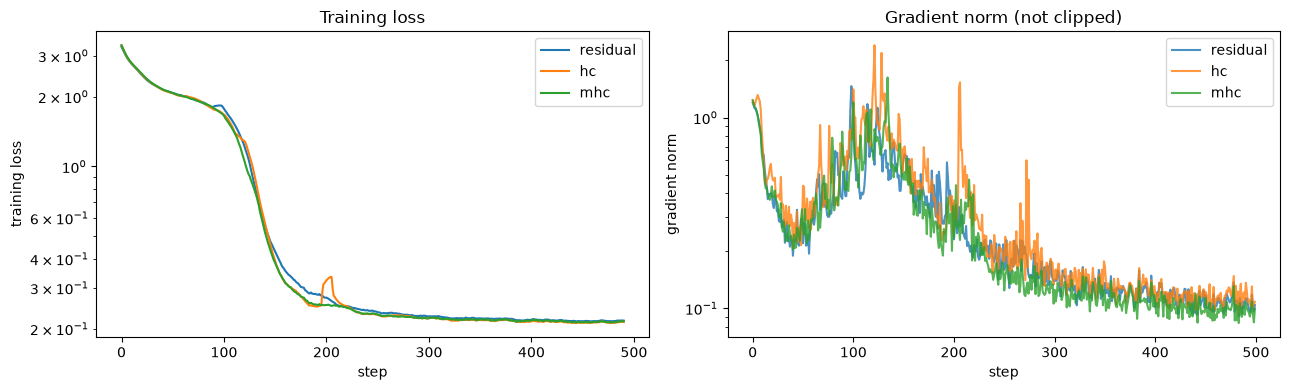

In [5]:
def get_batch(src, B=32):
    ix = torch.randint(0, len(src) - 129, (B,), device=device)
    return src[ix[:, None] + torch.arange(128, device=src.device)], src[ix[:, None] + torch.arange(1, 129, device=src.device)]

def train(mode, steps=500, lr=4e-3):
    seed_everything(0); m = LM(mode).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1); losses, gnorms = [], []
    for s in range(steps):
        x, y = get_batch(train_data); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward()
        gnorms.append(torch.nn.utils.clip_grad_norm_(m.parameters(), 1e9).item())             # measure, don't clip
        opt.step(); sched.step(); losses.append(loss.item())
    m.eval()
    with torch.no_grad(): val = np.mean([F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item() for x, y in (get_batch(val_data) for _ in range(10))])
    return m, losses, gnorms, val

runs = {}
for mode in ["residual", "hc", "mhc"]:
    t0 = time.time(); runs[mode] = train(mode)
    print(f"{mode:9s} val loss {runs[mode][3]:.4f} | max grad norm {max(runs[mode][2]):8.1f} | {time.time() - t0:.0f}s")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for mode, (_, l, g, _) in runs.items():
    axes[0].plot(np.convolve(l, np.ones(10) / 10, "valid"), label=mode); axes[1].semilogy(g, label=mode, alpha=0.8)
axes[0].set(xlabel="step", ylabel="training loss", yscale="log", title="Training loss"); axes[0].legend()
axes[1].set(xlabel="step", ylabel="gradient norm", title="Gradient norm (not clipped)"); axes[1].legend(); plt.tight_layout(); plt.show()

## The composite gain across depth
Multiply the per-layer $H^{res}$ matrices through all 24 sub-layers, for real tokens, and measure the paper's **Amax gain**: max absolute row sum (forward signal) and max absolute column sum (backward gradient). Doubly stochastic matrices keep both at 1.

hc   composite gain after 24 sub-layers: forward 0.638, backward 0.681 (max over depth: 1.271 / 1.319)
mhc  composite gain after 24 sub-layers: forward 1.000, backward 1.778 (max over depth: 1.000 / 1.778)


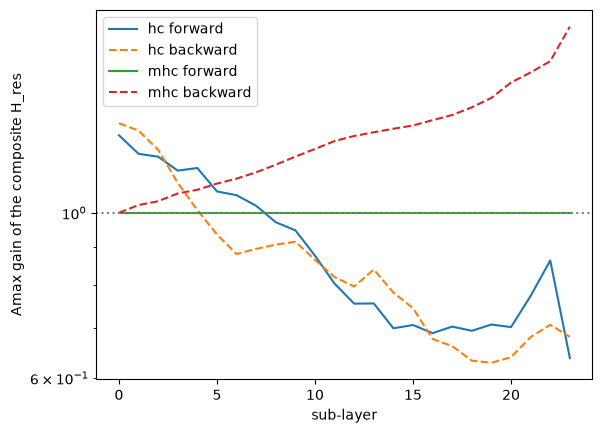

In [6]:
x, _ = get_batch(val_data, B=4)
for mode in ["hc", "mhc"]:
    m = runs[mode][0]
    with torch.no_grad(): m(x)
    P = torch.eye(4, device=device).expand(4, 128, 4, 4)
    gains = []
    for l in m.layers:
        P = l.last_res @ P
        gains.append((P.abs().sum(-1).amax().item(), P.abs().sum(-2).amax().item()))
    fwd, bwd = zip(*gains)
    print(f"{mode:4s} composite gain after 24 sub-layers: forward {fwd[-1]:.3f}, backward {bwd[-1]:.3f} (max over depth: {max(fwd):.3f} / {max(bwd):.3f})")
    plt.plot(fwd, label=f"{mode} forward"); plt.plot(bwd, "--", label=f"{mode} backward")
plt.axhline(1, c="gray", ls=":"); plt.xlabel("sub-layer"); plt.ylabel("Amax gain of the composite H_res"); plt.legend(); plt.yscale("log"); plt.show()

## Takeaways
- Several residual streams with learned mixing give the network more ways to route information than a single residual stream.
- Left unconstrained, the mixing matrices can amplify the signal and gradients through depth. The doubly-stochastic constraint keeps the composite map's gain at 1 by construction, whatever is learned.
- Reading the numbers above: mHC's forward gain is exactly 1 (Sinkhorn ends with a row normalisation), and its backward gain drifts a little above 1 because 20 iterations are only *approximately* doubly stochastic. The paper reports the same effect, a composite maximum of about 1.6. Unconstrained HC drifts away from 1 freely. Here, at toy scale, it *attenuated* the signal; at 27B the paper saw it amplify to about 3000, with loss spikes.
- The loss differences at this scale are small; the paper's instabilities appeared at 27B parameters and tens of thousands of steps. The gain measurement shows the mechanism directly, and that is why DeepSeek-V4 ships mHC rather than plain HC.